In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive



---
# **Importación de Librerías Base**
---


In [ ]:
import numpy as np
import pandas as pd



---
# **(Dtypes)**
---


In [ ]:
def inferir_dtypes_optimos(ruta, sep=",", encoding="utf-8", n_muestra=200_000,
                            umbral_categoria=0.5):
    """
    Lee una muestra del archivo y devuelve un dict {columna: dtype} con el
    tipo más liviano posible para cada columna, para usar luego en
    pd.read_csv(..., dtype=...).
    """
    muestra = pd.read_csv(ruta, sep=sep, encoding=encoding, nrows=n_muestra,
                           low_memory=False)

    dtypes = {}
    for col in muestra.columns:
        serie = muestra[col]

        if pd.api.types.is_integer_dtype(serie) or (
            pd.api.types.is_float_dtype(serie) and serie.dropna().apply(float.is_integer).all()
        ):
            # ¿tiene NaN? si sí, no puede ser un int de numpy puro -> usar Int (nullable)
            tiene_nulos = serie.isna().any()
            minimo, maximo = serie.min(), serie.max()
            for tipo in (["int8", "int16", "int32", "int64"]):
                info = np.iinfo(tipo)
                if info.min <= minimo and maximo <= info.max:
                    dtypes[col] = f"Int{tipo[3:]}" if tiene_nulos else tipo
                    break

        elif pd.api.types.is_float_dtype(serie):
            dtypes[col] = "float32"

        elif pd.api.types.is_object_dtype(serie) or pd.api.types.is_string_dtype(serie):
            n_unicos = serie.nunique(dropna=True)
            n_total = len(serie.dropna())
            if n_total > 0 and (n_unicos / n_total) < umbral_categoria:
                dtypes[col] = "category"
            # si no, se deja sin especificar (queda como object/string)

    return dtypes


---
# **Función de Carga Optimizada de CSV**
---


In [ ]:
def cargar_csv_completo_optimizado(ruta, sep=",", encoding="utf-8",
                                    chunksize=200_000, n_muestra=200_000):
    """
    Carga el CSV completo, con TODAS las columnas, aplicando dtypes
    optimizados desde la lectura (no después). Devuelve un único
    DataFrame final.
    """
    print("Inferiendo tipos óptimos a partir de una muestra...")
    dtypes = inferir_dtypes_optimos(ruta, sep=sep, encoding=encoding,
                                     n_muestra=n_muestra)
    print("Tipos detectados:")
    for col, tipo in dtypes.items():
        print(f"  {col}: {tipo}")

    partes = []
    lector = pd.read_csv(ruta, sep=sep, encoding=encoding, dtype=dtypes,
                          chunksize=chunksize, low_memory=False)

    total = 0
    for i, chunk in enumerate(lector, start=1):
        partes.append(chunk)
        total += len(chunk)
        print(f"  chunk {i}: {len(chunk):,} filas leídas (acumulado {total:,})")

    df = pd.concat(partes, ignore_index=True)

    # category no siempre sobrevive el pd.concat entre chunks con distintas
    # categorías -> reforzarlo al final
    for col, tipo in dtypes.items():
        if tipo == "category" and col in df.columns:
            df[col] = df[col].astype("category")

    return df



---
# **Carga del Dataset desde Google Drive**
---


In [ ]:
df = cargar_csv_completo_optimizado(
    "/content/drive/MyDrive/Proyecto IA/df.csv",
    sep=",", encoding="latin-1",       # ajusta a lo que ya confirmaste que funciona
    chunksize=100_000,
    n_muestra=200_000,
)

Inferiendo tipos óptimos a partir de una muestra...
Tipos detectados:
  PERIODO.x: int32
  MES.x: int8
  PER.x: int16
  DIRECTORIO: int32
  SECUENCIA_P: int8
  ORDEN: int8
  HOGAR.x: int8
  REGIS.x: int8
  AREA.x: Int8
  CLASE.x: int8
  FEX_C18.x: float32
  DPTO.x: int8
  PT: int8
  P6016: int8
  P3271: int8
  P6040: int8
  P6030S1: Int8
  P6030S3: Int16
  P6050: int8
  P6083: int8
  P6083S1: Int8
  P6081: int8
  P6081S1: Int8
  P2057: int8
  P2059: Int8
  P2061: int8
  P6080: int8
  P6080S1: category
  P6070: Int8
  P6071: Int8
  P6071S1: Int8
  P6090: int8
  P6100: Int8
  P6110: Int8
  P6120: Int32
  P1906S1: int8
  P1906S2: int8
  P1906S3: int8
  P1906S4: int8
  P1906S5: int8
  P1906S6: int8
  P1906S7: int8
  P1906S8: int8
  P6160: Int8
  P6170: Int8
  P3041: Int8
  P3042: Int8
  P3042S1: Int8
  P3042S2: Int16
  P3043: Int8
  P3043S1: Int16
  P3038: Int8
  P3039: Int8
  POB_MAY18: Int8
  PERIODO.y: Int32
  MES.y: Int8
  PER.y: Int16
  HOGAR.y: Int8
  REGIS.y: Int8
  AREA.y: Int8
  C


---
# **Visualización Inicial de Datos Cargados**
---


In [ ]:
df.head(10)

,PERIODO.x,MES.x,PER.x,DIRECTORIO,SECUENCIA_P,ORDEN,HOGAR.x,REGIS.x,AREA.x,CLASE.x,...,P3369,P3370,P3370S1,P3371,P3371S1,P3371S2,P3371S3,P3371S4,P3372,P3372S1
0,20250105,1,2025,8086872,1,1,1,10,<NA>,2,...,0,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
1,20250105,1,2025,8086874,1,1,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
2,20250105,1,2025,8086874,1,2,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
3,20250105,1,2025,8086874,1,3,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
4,20250105,1,2025,8086875,1,1,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
5,20250105,1,2025,8086876,1,1,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
6,20250105,1,2025,8086876,1,2,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
7,20250105,1,2025,8086876,1,3,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
8,20250105,1,2025,8086877,1,1,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>
9,20250105,1,2025,8086877,1,2,1,10,<NA>,2,...,<NA>,2,<NA>,2,<NA>,<NA>,<NA>,<NA>,2,<NA>



---
# **Dimensión del Dataset Original**
---


In [ ]:
df.shape

(817550, 579)


---
# **Algoritmo de Cálculo del IPM**
---


In [ ]:
import pandas as pd
import numpy as np

def calcular_ipm_geih(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calcula el Índice de Pobreza Multidimensional (IPM) ajustado
    según la metodología oficial adaptada a la GEIH 2025 (DANE).

    Devuelve el DataFrame original con:
        - IPM_PONDERADO     (score continuo 0-1)
        - CLASIFICADOR_IPM  (1 = pobre multidimensional, 0 = no pobre)
    """
    df = df.copy()
    df.columns = [c.upper().strip() for c in df.columns]

    KEYS_HOGAR   = ['DIRECTORIO', 'SECUENCIA_P']
    KEYS_PERSONA = ['DIRECTORIO', 'SECUENCIA_P', 'ORDEN']

    # ------------------------------------------------------------------
    # Helper seguro para obtener columnas (evita KeyError y maneja NA)
    # ------------------------------------------------------------------
    def col(name, default=np.nan):
        if name in df.columns:
            return df[name]
        return pd.Series(default, index=df.index)

    # ------------------------------------------------------------------
    # 0. Variables transversales
    # ------------------------------------------------------------------
    # CLASE (1 = Cabecera, 2 = Centro poblado / Rural)
    clase_cols = [c for c in df.columns if c.startswith('CLASE')]
    if clase_cols:
        df['CLASE'] = df[clase_cols].bfill(axis=1).iloc[:, 0]
    else:
        df['CLASE'] = np.nan

    # ------------------------------------------------------------------
    # 1. Años de escolaridad (P3042 + P3042S1) – lógica oficial 2025
    # ------------------------------------------------------------------
    def calcular_anos_escolaridad(row):
        nivel = row.get('P3042')
        grado = row.get('P3042S1')

        # Cualquier NA o códigos especiales → 0 años
        if pd.isna(nivel) or nivel in [1, 99]:
            return 0.0

        grado_val = 0.0 if pd.isna(grado) else float(grado)

        if nivel == 2:                       # Preescolar
            return 0.0
        elif nivel == 3:                     # Primaria
            return min(grado_val, 5.0)
        elif nivel == 4:                     # Secundaria (6º-9º)
            return 5.0 + min(grado_val, 4.0)
        elif nivel in [5, 6]:                # Media académica / técnica
            return 9.0 + min(grado_val, 2.0)
        elif nivel in [7, 8, 9, 10, 11, 12, 13]:  # Superior y postgrados
            return 11.0 + grado_val
        return 0.0

    df['ANOS_EDUC'] = df.apply(calcular_anos_escolaridad, axis=1)

    # ------------------------------------------------------------------
    # 2. Dimensión Educación (20 %)
    # ------------------------------------------------------------------
    # 2.1 Bajo logro educativo
    df_15mas = df[df['P6040'] >= 15]
    prom_educ = (df_15mas.groupby(KEYS_HOGAR)['ANOS_EDUC']
                        .mean()
                        .reset_index()
                        .rename(columns={'ANOS_EDUC': 'PROM_ANOS_EDUC'}))
    df = df.merge(prom_educ, on=KEYS_HOGAR, how='left')

    df['PRIV_BAJO_LOGRO'] = np.where(
        df['PROM_ANOS_EDUC'].isna() | (df['PROM_ANOS_EDUC'] < 9.0), 1, 0
    )

    # 2.2 Analfabetismo
    p6160 = col('P6160').fillna(-1)
    df['ANALFABETA_IND'] = np.where(
        (df['P6040'] >= 15) & (p6160 == 2), 1, 0
    )
    priv = df.groupby(KEYS_HOGAR)['ANALFABETA_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_ANALFABETISMO']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # ------------------------------------------------------------------
    # 3. Dimensión Niñez y Juventud (20 %)
    # ------------------------------------------------------------------
    # 3.1 Rezago escolar
    def evaluar_rezago(row):
        edad = row.get('P6040')
        esc  = row.get('ANOS_EDUC', 0)
        if pd.isna(edad):
            return 0
        if 7 <= edad <= 17:
            return 1 if esc < (edad - 7) else 0
        return 0

    df['REZAGO_IND'] = df.apply(evaluar_rezago, axis=1)
    priv = df.groupby(KEYS_HOGAR)['REZAGO_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_REZAGO_ESCOLAR']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # 3.2 Inasistencia escolar
    p6170 = col('P6170').fillna(-1)
    df['INASISTENCIA_IND'] = np.where(
        (df['P6040'].between(6, 16)) & (p6170 == 2), 1, 0
    )
    priv = df.groupby(KEYS_HOGAR)['INASISTENCIA_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_INASISTENCIA_ESCOLAR']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # 3.3 Barreras a servicios de cuidado de primera infancia
    p6050 = col('P6050').fillna(-1)
    p6170 = col('P6170').fillna(-1)

    cond_infancia = (
        (df['P6040'] <= 5) &
        (
            ((df['P6040'] >= 3) & (p6170 == 2)) |
            (p6050.isin([3, 4]) & (p6170 == 2))
        )
    )
    # Forzar boolean puro
    cond_infancia = cond_infancia.fillna(False).astype(bool)
    df['BARRERA_INFANCIA_IND'] = np.where(cond_infancia, 1, 0)

    priv = df.groupby(KEYS_HOGAR)['BARRERA_INFANCIA_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_PRIMERA_INFANCIA']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # 3.4 Trabajo infantil (usa OCI del diccionario 2025)
    oci = col('OCI').fillna(0)
    df['TRABAJO_INFANTIL_IND'] = np.where(
        (df['P6040'].between(12, 17)) & (oci == 1), 1, 0
    )
    priv = df.groupby(KEYS_HOGAR)['TRABAJO_INFANTIL_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_TRABAJO_INFANTIL']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # ------------------------------------------------------------------
    # 4. Dimensión Salud (20 %)
    # ------------------------------------------------------------------
    # 4.1 Sin aseguramiento en salud
    p6090 = col('P6090').fillna(-1)
    df['SIN_SALUD_IND'] = np.where(
        (df['P6040'] > 5) & (p6090.isin([2, 9])), 1, 0
    )
    priv = df.groupby(KEYS_HOGAR)['SIN_SALUD_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_ASEGURAMIENTO_SALUD']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # 4.2 Barreras de acceso a servicios de salud
    # (la guía 2025 usa una aproximación; se deja robusta)
    p6100 = col('P6100').fillna(-1)
    df['BARRERA_ACCESO_SALUD_IND'] = np.where(
        (p6090 == 2) & (p6100.isna() | (p6100 == -1)), 1, 0
    )
    priv = df.groupby(KEYS_HOGAR)['BARRERA_ACCESO_SALUD_IND'].max().reset_index()
    priv.columns = KEYS_HOGAR + ['PRIV_ACCESO_SALUD']
    df = df.merge(priv, on=KEYS_HOGAR, how='left')

    # ------------------------------------------------------------------
    # 5. Dimensión Trabajo (20 %)
    # ------------------------------------------------------------------
    oci = col('OCI').fillna(0)
    dsi = col('DSI').fillna(0)
    p7250 = col('P7250').fillna(-1)
    p6920 = col('P6920').fillna(-1)

    # PEA
    df['PEA'] = np.where((oci == 1) | (dsi == 1), 1, 0)

    # 5.1 Desempleo de larga duración (≥ 52 semanas)
    df['DESEMPLEO_LARGO_IND'] = np.where(
        (dsi == 1) & (p7250 >= 52), 1, 0
    )

    hogar_des = df.groupby(KEYS_HOGAR).agg(
        TOTAL_PEA=('PEA', 'sum'),
        TIENE_DESEMPLEO_LARGO=('DESEMPLEO_LARGO_IND', 'max'),
        ES_PENSIONADO=('P6920', lambda x: (x.fillna(-1) == 3).all())
    ).reset_index()

    hogar_des['PRIV_DESEMPLEO_LARGO'] = np.where(
        (hogar_des['TIENE_DESEMPLEO_LARGO'] == 1) |
        ((hogar_des['TOTAL_PEA'] == 0) & (~hogar_des['ES_PENSIONADO'])),
        1, 0
    )
    df = df.merge(hogar_des[KEYS_HOGAR + ['PRIV_DESEMPLEO_LARGO']], on=KEYS_HOGAR, how='left')

    # 5.2 Empleo informal (≥ 50 % de ocupados son informales)
    df['OCUPADO_FORMAL'] = np.where(
        (oci == 1) & (p6920.isin([1, 3])), 1, 0
    )

    hogar_inf = df.groupby(KEYS_HOGAR).agg(
        TOTAL_OCUPADOS=('OCI', 'sum'),
        TOTAL_FORMALES=('OCUPADO_FORMAL', 'sum'),
        ES_PENSIONADO=('P6920', lambda x: (x.fillna(-1) == 3).all())
    ).reset_index()

    hogar_inf['PROP_INFORMAL'] = np.where(
        hogar_inf['TOTAL_OCUPADOS'] > 0,
        1.0 - (hogar_inf['TOTAL_FORMALES'] / hogar_inf['TOTAL_OCUPADOS']),
        1.0
    )

    hogar_inf['PRIV_EMPLEO_INFORMAL'] = np.where(
        (~hogar_inf['ES_PENSIONADO']) &
        (
            (hogar_inf['TOTAL_OCUPADOS'] == 0) |
            (hogar_inf['PROP_INFORMAL'] >= 0.50)
        ),
        1, 0
    )
    df = df.merge(hogar_inf[KEYS_HOGAR + ['PRIV_EMPLEO_INFORMAL']], on=KEYS_HOGAR, how='left')

    # ------------------------------------------------------------------
    # 6. Dimensión Vivienda y Servicios Públicos (20 %)
    # ------------------------------------------------------------------
    p4030s5 = col('P4030S5').fillna(-1)
    p5050   = col('P5050').fillna(-1)
    p5020   = col('P5020').fillna(-1)
    p4020   = col('P4020').fillna(-1)
    p4010   = col('P4010').fillna(-1)
    p5010   = col('P5010').fillna(np.nan)

    # 6.1 Fuente de agua mejorada
    cond_agua_urb = (df['CLASE'] == 1) & (p4030s5 != 1)
    cond_agua_rur = (df['CLASE'] != 1) & (p5050.isin([3, 4, 5, 6, 7, 9, 10]))
    df['PRIV_FUENTE_AGUA'] = np.where(
        (cond_agua_urb | cond_agua_rur).fillna(False), 1, 0
    )

    # 6.2 Eliminación de excretas
    df['PRIV_ELIMINACION_EXCRETAS'] = np.where(
        p5020.isin([3, 4, 5, 6]), 1, 0
    )

    # 6.3 Material de pisos
    df['PRIV_PISOS'] = np.where(p4020 == 1, 1, 0)

    # 6.4 Material de paredes
    df['PRIV_PAREDES'] = np.where(
        p4010.isin([4, 5, 6, 7, 8, 9]), 1, 0
    )

    # 6.5 Hacinamiento crítico
    n_pers = df.groupby(KEYS_HOGAR)['ORDEN'].count().reset_index()
    n_pers.columns = KEYS_HOGAR + ['N_PERSONAS']
    df = df.merge(n_pers, on=KEYS_HOGAR, how='left')

    df['PERSONAS_POR_CUARTO'] = df['N_PERSONAS'] / p5010.replace(0, np.nan)

    cond_hac_urb = (df['CLASE'] == 1) & (df['PERSONAS_POR_CUARTO'] >= 3.0)
    cond_hac_rur = (df['CLASE'] != 1) & (df['PERSONAS_POR_CUARTO'] > 3.0)
    df['PRIV_HACINAMIENTO'] = np.where(
        (cond_hac_urb | cond_hac_rur).fillna(False), 1, 0
    )

    # ------------------------------------------------------------------
    # 7. Agregación ponderada y clasificador Alkire-Foster
    # ------------------------------------------------------------------
    COLS_PRIVACIONES = [
        'PRIV_BAJO_LOGRO', 'PRIV_ANALFABETISMO',
        'PRIV_REZAGO_ESCOLAR', 'PRIV_INASISTENCIA_ESCOLAR',
        'PRIV_PRIMERA_INFANCIA', 'PRIV_TRABAJO_INFANTIL',
        'PRIV_ASEGURAMIENTO_SALUD', 'PRIV_ACCESO_SALUD',
        'PRIV_DESEMPLEO_LARGO', 'PRIV_EMPLEO_INFORMAL',
        'PRIV_FUENTE_AGUA', 'PRIV_ELIMINACION_EXCRETAS',
        'PRIV_PISOS', 'PRIV_PAREDES', 'PRIV_HACINAMIENTO'
    ]

    for c in COLS_PRIVACIONES:
        if c not in df.columns:
            df[c] = 0
        df[c] = df[c].fillna(0).astype(int)

    PESOS = np.array([
        0.10, 0.10,                     # Educación
        0.05, 0.05, 0.05, 0.05,         # Niñez y Juventud
        0.10, 0.10,                     # Salud
        0.10, 0.10,                     # Trabajo
        0.04, 0.04, 0.04, 0.04, 0.04    # Vivienda
    ])

    # Base a nivel de hogar
    df_hog = (df.groupby(KEYS_HOGAR)[COLS_PRIVACIONES]
                .first()
                .reset_index())

    matriz = df_hog[COLS_PRIVACIONES].values
    df_hog['IPM_PONDERADO'] = np.dot(matriz, PESOS)
    df_hog['CLASIFICADOR_IPM'] = (df_hog['IPM_PONDERADO'] >= (5.0 / 15.0)).astype(int)

    # Unir de nuevo al DataFrame de personas
    df = df.drop(columns=[c for c in ['IPM_PONDERADO', 'CLASIFICADOR_IPM'] if c in df.columns],
                 errors='ignore')
    df = df.merge(df_hog[KEYS_HOGAR + ['IPM_PONDERADO', 'CLASIFICADOR_IPM']],
                  on=KEYS_HOGAR, how='left')

    return df


---
# **Cálculo de IPM y Distribución de Resultados**
---


In [ ]:
df_ipm = calcular_ipm_geih(df)

# Distribución del clasificador
print(df_ipm['CLASIFICADOR_IPM'].value_counts(normalize=True).round(4))

# Resumen del score
print(df_ipm.groupby('CLASIFICADOR_IPM')['IPM_PONDERADO'].describe().round(4))

/tmp/ipykernel_761/692806978.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['CLASE'] = df[clase_cols].bfill(axis=1).iloc[:, 0]


CLASIFICADOR_IPM
0    0.8916
1    0.1084
Name: proportion, dtype: float64
                     count    mean     std   min   25%  50%   75%   max
CLASIFICADOR_IPM                                                       
0                 728965.0  0.1297  0.0998  0.00  0.04  0.1  0.20  0.33
1                  88585.0  0.4191  0.0773  0.34  0.35  0.4  0.45  0.95



---
# **Filtrado de Variables Críticas**
---


In [ ]:
# Definir las columnas necesarias para el cálculo del IPM según la lógica implementada
columnas_necesarias = [
    # Identificadores
    'DIRECTORIO', 'SECUENCIA_P', 'ORDEN',

    # Transversales y demográficas
    'CLASE', 'CLASE.x', 'CLASE.y', 'P6040',  # Edad y Clase

    # Dimensión Educación
    'P3042', 'P3042S1', 'P6160',

    # Dimensión Niñez y Juventud
    'P6170', 'P6050', 'OCI',

    # Dimensión Salud
    'P6090', 'P6100',

    # Dimensión Trabajo
    'DSI', 'P7250', 'P6920',

    # Dimensión Vivienda y Servicios Públicos
    'P4030S5', 'P5050', 'P5020', 'P4020', 'P4010', 'P5010'
]

# Filtrar las columnas que realmente existen en el DataFrame original para evitar KeyErrors
columnas_presentes = [col for col in df.columns if col.upper().strip() in [c.upper() for c in columnas_necesarias]]

# Crear el DataFrame filtrado
df_filtrado = df[columnas_presentes].copy()

print(f"Dataset original: {df.shape[1]} columnas.")
print(f"Dataset filtrado: {df_filtrado.shape[1]} columnas.")
display(df_filtrado.head())


Dataset original: 579 columnas.
Dataset filtrado: 23 columnas.


,DIRECTORIO,SECUENCIA_P,ORDEN,CLASE.x,P6040,P6050,P6090,P6100,P6160,P6170,...,P6920,OCI,P4010,P4020,P4030S5,P5010,P5020,P5050,DSI,P7250
0,8086872,1,1,2,54,1,1,3,1,2,...,2,1,1,2,1,2,2,8,<NA>,<NA>
1,8086874,1,1,2,79,1,1,3,1,2,...,<NA>,<NA>,1,2,1,2,2,8,<NA>,<NA>
2,8086874,1,2,2,60,9,1,3,1,2,...,2,1,1,2,1,2,2,8,<NA>,<NA>
3,8086874,1,3,2,59,9,1,3,1,2,...,2,1,1,2,1,2,2,8,<NA>,<NA>
4,8086875,1,1,2,80,1,1,2,1,2,...,<NA>,<NA>,1,4,1,1,2,9,<NA>,<NA>



---
# **Unión de CLASIFICADOR_IPM al Dataset Filtrado**
---


In [ ]:
# Aseguramos que contamos con las llaves de unión necesarias en el DataFrame filtrado
llaves_hogar = ['DIRECTORIO', 'SECUENCIA_P']

# Extraemos las llaves y el clasificador final de df_ipm eliminando duplicados a nivel de persona/hogar
etiquetas_ipm = df_ipm[llaves_hogar + ['CLASIFICADOR_IPM', 'IPM_PONDERADO']].drop_duplicates()

# Unimos la etiqueta al DataFrame filtrado
df_filtrado = df_filtrado.merge(etiquetas_ipm, on=llaves_hogar, how='left')

print(f"Dimensiones de df_filtrado: {df_filtrado.shape}")
print("\nDistribución del Clasificador IPM en el dataset filtrado:")
print(df_filtrado['CLASIFICADOR_IPM'].value_counts(dropna=False))

display(df_filtrado.head())


Dimensiones de df_filtrado: (817550, 25)

Distribución del Clasificador IPM en el dataset filtrado:
CLASIFICADOR_IPM
0    728965
1     88585
Name: count, dtype: int64


,DIRECTORIO,SECUENCIA_P,ORDEN,CLASE.x,P6040,P6050,P6090,P6100,P6160,P6170,...,P4010,P4020,P4030S5,P5010,P5020,P5050,DSI,P7250,CLASIFICADOR_IPM,IPM_PONDERADO
0,8086872,1,1,2,54,1,1,3,1,2,...,1,2,1,2,2,8,<NA>,<NA>,0,0.20
1,8086874,1,1,2,79,1,1,3,1,2,...,1,2,1,2,2,8,<NA>,<NA>,0,0.20
2,8086874,1,2,2,60,9,1,3,1,2,...,1,2,1,2,2,8,<NA>,<NA>,0,0.20
3,8086874,1,3,2,59,9,1,3,1,2,...,1,2,1,2,2,8,<NA>,<NA>,0,0.20
4,8086875,1,1,2,80,1,1,2,1,2,...,1,4,1,1,2,9,<NA>,<NA>,0,0.24



---
# **Copia**
---


In [ ]:
df_limpio = df_filtrado


---
# **Limpieza de Identificadores innecesarios**
---


In [ ]:
# Definir los identificadores a eliminar
columnas_identificadores = ['DIRECTORIO', 'SECUENCIA_P', 'ORDEN', 'IPM_PONDERADO']

# Aseguramos que df_limpio contenga la etiqueta unida antes de eliminar
df_limpio = df_filtrado.copy()

# Eliminar los identificadores si existen en el DataFrame
df_limpio = df_limpio.drop(columns=[col for col in columnas_identificadores if col in df_limpio.columns])

print(f"Dimensiones finales de df_limpio: {df_limpio.shape}")
print("Columnas restantes en el dataset:")
print(list(df_limpio.columns))
display(df_limpio.head())


Dimensiones finales de df_limpio: (817550, 21)
Columnas restantes en el dataset:
['CLASE.x', 'P6040', 'P6050', 'P6090', 'P6100', 'P6160', 'P6170', 'P3042', 'P3042S1', 'CLASE.y', 'P6920', 'OCI', 'P4010', 'P4020', 'P4030S5', 'P5010', 'P5020', 'P5050', 'DSI', 'P7250', 'CLASIFICADOR_IPM']


,CLASE.x,P6040,P6050,P6090,P6100,P6160,P6170,P3042,P3042S1,CLASE.y,...,OCI,P4010,P4020,P4030S5,P5010,P5020,P5050,DSI,P7250,CLASIFICADOR_IPM
0,2,54,1,1,3,1,2,3,5,2,...,1,1,2,1,2,2,8,<NA>,<NA>,0
1,2,79,1,1,3,1,2,3,5,<NA>,...,<NA>,1,2,1,2,2,8,<NA>,<NA>,0
2,2,60,9,1,3,1,2,4,4,2,...,1,1,2,1,2,2,8,<NA>,<NA>,0
3,2,59,9,1,3,1,2,4,4,2,...,1,1,2,1,2,2,8,<NA>,<NA>,0
4,2,80,1,1,2,1,2,10,10,<NA>,...,<NA>,1,4,1,1,2,9,<NA>,<NA>,0



---
# **Estrategia Avanzada de Nulos: Variables Indicadoras y Reemplazo por -1**
---


In [ ]:
import pandas as pd
import numpy as np

# 1. Crear una copia de trabajo
df_imputado_indicador = df_limpio.copy()

# 2. Identificar características (excluyendo el objetivo)
target_col = 'CLASIFICADOR_IPM'
features = [col for col in df_imputado_indicador.columns if col != target_col]

# 3. Aplicar la estrategia: Crear columna indicadora y rellenar nulos con -1
columnas_con_na = []
for col in features:
    if df_imputado_indicador[col].isna().any():
        columnas_con_na.append(col)
        # Crear la columna indicadora (1 si es nulo, 0 si no)
        indicadora_col_name = f"{col}_es_na"
        df_imputado_indicador[indicadora_col_name] = df_imputado_indicador[col].isna().astype(np.int8)

        # Rellenar los valores nulos en la columna original con -1
        # Convertimos temporalmente a tipo float/int estándar de pandas para evitar restricciones de tipos Nullable
        df_imputado_indicador[col] = df_imputado_indicador[col].astype(float).fillna(-1.0)

print(f"Columnas modificadas por tener nulos: {columnas_con_na}")
print(f"Forma original de df_limpio: {df_limpio.shape}")
print(f"Nueva forma de df_imputado_indicador: {df_imputado_indicador.shape}")
print("\nPrimeras filas del nuevo dataset procesado:")
display(df_imputado_indicador.head())


Columnas modificadas por tener nulos: ['P6100', 'P6160', 'P6170', 'P3042', 'P3042S1', 'CLASE.y', 'P6920', 'OCI', 'DSI', 'P7250']
Forma original de df_limpio: (817550, 21)
Nueva forma de df_imputado_indicador: (817550, 31)

Primeras filas del nuevo dataset procesado:


,CLASE.x,P6040,P6050,P6090,P6100,P6160,P6170,P3042,P3042S1,CLASE.y,...,P6100_es_na,P6160_es_na,P6170_es_na,P3042_es_na,P3042S1_es_na,CLASE.y_es_na,P6920_es_na,OCI_es_na,DSI_es_na,P7250_es_na
0,2,54,1,1,3.0,1.0,2.0,3.0,5.0,2.0,...,0,0,0,0,0,0,0,0,1,1
1,2,79,1,1,3.0,1.0,2.0,3.0,5.0,-1.0,...,0,0,0,0,0,1,1,1,1,1
2,2,60,9,1,3.0,1.0,2.0,4.0,4.0,2.0,...,0,0,0,0,0,0,0,0,1,1
3,2,59,9,1,3.0,1.0,2.0,4.0,4.0,2.0,...,0,0,0,0,0,0,0,0,1,1
4,2,80,1,1,2.0,1.0,2.0,10.0,10.0,-1.0,...,0,0,0,0,0,1,1,1,1,1


In [ ]:
df_imputado_indicador.columns

Index(['CLASE.x', 'P6040', 'P6050', 'P6090', 'P6100', 'P6160', 'P6170',
       'P3042', 'P3042S1', 'CLASE.y', 'P6920', 'OCI', 'P4010', 'P4020',
       'P4030S5', 'P5010', 'P5020', 'P5050', 'DSI', 'P7250',
       'CLASIFICADOR_IPM', 'P6100_es_na', 'P6160_es_na', 'P6170_es_na',
       'P3042_es_na', 'P3042S1_es_na', 'CLASE.y_es_na', 'P6920_es_na',
       'OCI_es_na', 'DSI_es_na', 'P7250_es_na'],
      dtype='object')

In [ ]:
def tpr(est,X,y):
    p = est.predict(X)
    return np.mean (p[y==1] == y[y==1])

def tnr(est,X,y):
    p = est.predict(X)
    return np.mean(p[y==0] == y[y==0])



---
# **Regresor Logístico**
---





In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression

def logisticRegressor(X_train, y_train, X_test, y_test):
    modelo_log = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
    modelo_log.fit(X_train, y_train)

    preds = modelo_log.predict(X_test)
    conf_matrix = confusion_matrix(y_test, preds)
    acc_score = accuracy_score(y_test, preds)

    # Convertir a dict para extraer métricas individuales
    report_dict = classification_report(y_test, preds, output_dict=True)

    # Usamos claves '0' y '1' (cadenas de enteros, típicas de sklearn)
    # Eliminamos el formato :.4f de la comparación lógica
    p_clase_0 = report_dict.get('0', report_dict.get('0.0', {})).get('precision', 0.0)
    r_clase_1 = report_dict.get('1', report_dict.get('1.0', {})).get('recall', 0.0)


    print("Confusion Matrix:\n", conf_matrix)
    print(f"Class 0 Precision: {p_clase_0:.4f}")
    print(f"Class 1 Recall:    {r_clase_1:.4f}")
    print(f"Overall Accuracy:  {report_dict['accuracy']:.4f}")
    print("Accuracy Score:", acc_score)
    print(classification_report(y_test, preds))
    return True

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

datos_modelo = df_imputado_indicador.dropna(subset=['CLASIFICADOR_IPM']).copy()

# 1. Inicializar y entrenar el Árbol de Decisión
X_exp = datos_modelo.drop(columns=['CLASIFICADOR_IPM'])
X_exp = datos_modelo.drop(columns=['CLASE.x','P6050', 'P6090', 'P6170',
       'P3042S1', 'CLASE.y', 'P6920', 'OCI',
       'P4030S5', 'P5010', 'P5020', 'P5050', 'DSI', 'P7250',
       'CLASIFICADOR_IPM', 'P6160_es_na', 'P6170_es_na',
       'P3042_es_na', 'P3042S1_es_na', 'CLASE.y_es_na', 'P6920_es_na',
       'OCI_es_na', 'DSI_es_na', 'P7250_es_na'])
y_exp = datos_modelo['CLASIFICADOR_IPM'].astype(int)

X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
  X_exp, y_exp, test_size=0.3, random_state=42, stratify=y_exp, shuffle=True
)

X_train_scaled=scaler.fit_transform(X_train_exp)
X_test_scaled=scaler.transform(X_test_exp)

results=logisticRegressor(X_train=X_train_scaled, y_train=y_train_exp, X_test=X_test_scaled, y_test=y_test_exp)

results2=decissionTree(X_train=X_train_scaled, y_train=y_train_exp, X_test=X_test_scaled, y_test=y_test_exp)

results3=randomForest(X_train=X_train_scaled, y_train=y_train_exp, X_test=X_test_scaled, y_test=y_test_exp)

modelo_arbol = DecisionTreeClassifier(random_state=42, max_depth=10, class_weight='balanced')
modelo_arbol.fit(X_train_scaled, y_train_exp)
y_pred_arbol = modelo_arbol.predict(X_test_scaled)

# Calcular métricas para el Árbol
acc_arbol = accuracy_score(y_test_exp, y_pred_arbol)
rec_arbol = recall_score(y_test_exp, y_pred_arbol, zero_division=0)

print("=== Evaluación del Árbol de Decisión ===")
print(f"Accuracy Score: {acc_arbol:.4f}")
print(f"Recall (Clase 1 - Pobre): {rec_arbol:.4f}")
print("-" * 40)

feature_importances_series = pd.Series(modelo_arbol.feature_importances_, index=X_train_exp.columns)
sorted_feature_importances = feature_importances_series.sort_values(ascending=False)
print(sorted_feature_importances)

NameError: name 'decissionTree' is not defined

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier


def decissionTree(X_train, y_train, X_test, y_test):
    modelo_dt = DecisionTreeClassifier(class_weight="balanced")

    param_grid = {
    'max_depth': [3, 5, 7, 10],
    }


    # 4. Configure GridSearchCV with classification scoring (e.g., 'accuracy')
    grid_search_clf = GridSearchCV(estimator=modelo_dt, param_grid=param_grid, scoring='accuracy', cv=5)

    # 5. Fit the model to find the best hyperparameters
    grid_search_clf.fit(X_train, y_train)

    # 6. View best parameters and best estimator
    #print("Best Parameters found:", grid_search_clf.best_params_)
    #print(f"Best Cross-Validation Accuracy: {grid_search_clf.best_score_:.4f}")

    best_model = grid_search_clf.best_estimator_
    preds = best_model.predict(X_test)

    conf_matrix = confusion_matrix(y_test, preds)
    acc_score = accuracy_score(y_test, preds)

    # Convertir a dict para extraer métricas individuales
    report_dict = classification_report(y_test, preds, output_dict=True)

    # Usamos claves '0' y '1' (cadenas de enteros, típicas de sklearn)
    # Eliminamos el formato :.4f de la comparación lógica
    p_clase_0 = report_dict.get('0', report_dict.get('0.0', {})).get('precision', 0.0)
    r_clase_1 = report_dict.get('1', report_dict.get('1.0', {})).get('recall', 0.0)
    test_specificity = tnr(best_model, X_test, y_test)

    performance = False


    print("Confusion Matrix:\n", conf_matrix)
    print(f"Class 0 Precision: {p_clase_0:.4f}")
    print(f"Class 1 Recall:    {r_clase_1:.4f}")
    print(f"Overall Accuracy:  {report_dict['accuracy']:.4f}")
    print(f"Specificity: {test_specificity:.4f}")
    print(classification_report(y_test, preds))
    performance= True

    return [performance, p_clase_0, r_clase_1, report_dict['accuracy'], test_specificity]

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier


def randomForest(X_train, y_train, X_test, y_test):
    modelo_rf = RandomForestClassifier(class_weight="balanced")

    param_grid = {
    'n_estimators': [10, 50, 100],
    'max_depth': [3, 5, None],
    'criterion': ['gini', 'entropy']
    }


    # 4. Configure GridSearchCV with classification scoring (e.g., 'accuracy')
    grid_search_clf = GridSearchCV(estimator=modelo_rf, param_grid=param_grid, scoring='accuracy', cv=5)

    # 5. Fit the model to find the best hyperparameters
    grid_search_clf.fit(X_train, y_train)

    # 6. View best parameters and best estimator
    #print("Best Parameters found:", grid_search_clf.best_params_)
    #print(f"Best Cross-Validation Accuracy: {grid_search_clf.best_score_:.4f}")

    best_model = grid_search_clf.best_estimator_
    preds = best_model.predict(X_test)

    conf_matrix = confusion_matrix(y_test, preds)
    acc_score = accuracy_score(y_test, preds)

    # Convertir a dict para extraer métricas individuales
    report_dict = classification_report(y_test, preds, output_dict=True)

    # Usamos claves '0' y '1' (cadenas de enteros, típicas de sklearn)
    # Eliminamos el formato :.4f de la comparación lógica
    p_clase_0 = report_dict.get('0', report_dict.get('0.0', {})).get('precision', 0.0)
    r_clase_1 = report_dict.get('1', report_dict.get('1.0', {})).get('recall', 0.0)
    test_specificity = tnr(best_model, X_test, y_test)

    performance = False


    print("Confusion Matrix:\n", conf_matrix)
    print(f"Class 0 Precision: {p_clase_0:.4f}")
    print(f"Class 1 Recall:    {r_clase_1:.4f}")
    print(f"Overall Accuracy:  {report_dict['accuracy']:.4f}")
    print(f"Specificity: {test_specificity:.4f}")
    print(classification_report(y_test, preds))
    performance= True

    return [performance, p_clase_0, r_clase_1, report_dict['accuracy'], test_specificity]

In [ ]:
import tensorflow as tf
from tensorflow import keras

model = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation=tf.nn.relu),
    tf.keras.layers.Dense(64, activation=tf.nn.relu),
    tf.keras.layers.Dense(32, activation=tf.nn.relu),
    tf.keras.layers.Dense(10, activation=tf.nn.relu),
    tf.keras.layers.Dense(2, activation=tf.nn.softmax),
])
model.summary()


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

datos_modelo = df_imputado_indicador.dropna(subset=['CLASIFICADOR_IPM']).copy()

X_exp = datos_modelo.drop(columns=['CLASIFICADOR_IPM'])
X_exp = datos_modelo.drop(columns=['CLASE.x','P6050', 'P6090', 'P6170',
       'P3042S1', 'CLASE.y', 'P6920', 'OCI',
       'P4030S5', 'P5010', 'P5020', 'P5050', 'DSI', 'P7250',
       'CLASIFICADOR_IPM', 'P6160_es_na', 'P6170_es_na',
       'P3042_es_na', 'P3042S1_es_na', 'CLASE.y_es_na', 'P6920_es_na',
       'OCI_es_na', 'DSI_es_na', 'P7250_es_na'])
y_exp = datos_modelo['CLASIFICADOR_IPM'].astype(int)

X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
  X_exp, y_exp, test_size=0.3, random_state=42, stratify=y_exp, shuffle=True
)

#X_train_exp, X_val, y_train_exp, y_val = train_test_split(
 # X_train_val, y_train_val, test_size=0.15, random_state=42, stratify=y_train_val, shuffle=True
#)

X_train_scaled=scaler.fit_transform(X_train_exp)
X_test_scaled=scaler.transform(X_test_exp)


classes = np.unique(y_train_exp)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_exp
)

class_weights= dict(zip(classes,weights))

print(class_weights)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

# Compilamos usando 'accuracy' que es totalmente compatible con etiquetas sparse
model.compile(optimizer=tf.keras.optimizers.SGD(),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# Entrenamos el modelo
model.fit(X_train_scaled, y_train_exp, epochs=3, class_weight=class_weights)

test_loss, test_acc = model.evaluate(X_test_scaled, y_test_exp)
print(f"Test Accuracy: {test_acc:.4f}")

# Realizamos las predicciones
predictions = model.predict(X_test_scaled)
labels_pred = np.argmax(predictions, axis=1)

# Calculamos y mostramos las métricas detalladas (incluyendo Precision y Recall)
print("\n=== Reporte de Clasificación (Test) ===")
print(classification_report(y_test_exp, labels_pred))

cm_test = confusion_matrix(y_test_exp, labels_pred)
print("Matriz de Confusión:\n", cm_test)

plt.imshow(cm_test, cmap='viridis')
plt.colorbar()
plt.title("Matriz de Confusión - Red Neuronal")
plt.show()



---

# **Random Forest**

---



In [ ]:
# 2. Inicializar y entrenar el Random Forest
# Usamos n_jobs=-1 para acelerar el entrenamiento en múltiples núcleos
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10, class_weight='balanced', n_jobs=-1)
modelo_rf.fit(X_train_imp, y_train_exp)
y_pred_rf = modelo_rf.predict(X_test_imp)

# Calcular métricas para el Random Forest
acc_rf = accuracy_score(y_test_exp, y_pred_rf)
rec_rf = recall_score(y_test_exp, y_pred_rf, zero_division=0)

print("=== Evaluación de Random Forest ===")
print(f"Accuracy Score: {acc_rf:.4f}")
print(f"Recall (Clase 1 - Pobre): {rec_rf:.4f}")


---
# **Reducción de Dimensionalidad (PCA & t-SNE) y Selección de Componentes**
---
En esta sección, aplicamos **PCA** para proyectar linealmente los datos y justificar la cantidad de componentes mediante la Varianza Explicada Acumulada. Posteriormente, utilizamos **t-SNE** para capturar relaciones no lineales en un espacio de 2 dimensiones, comparando visualmente ambas técnicas.
```

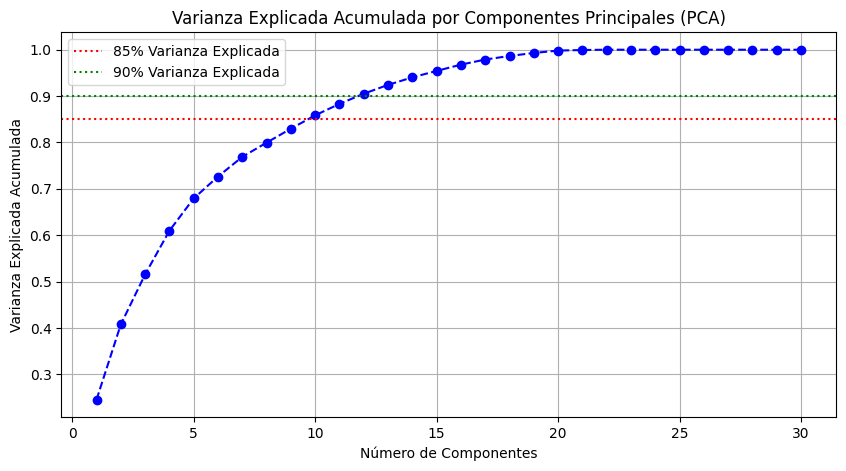

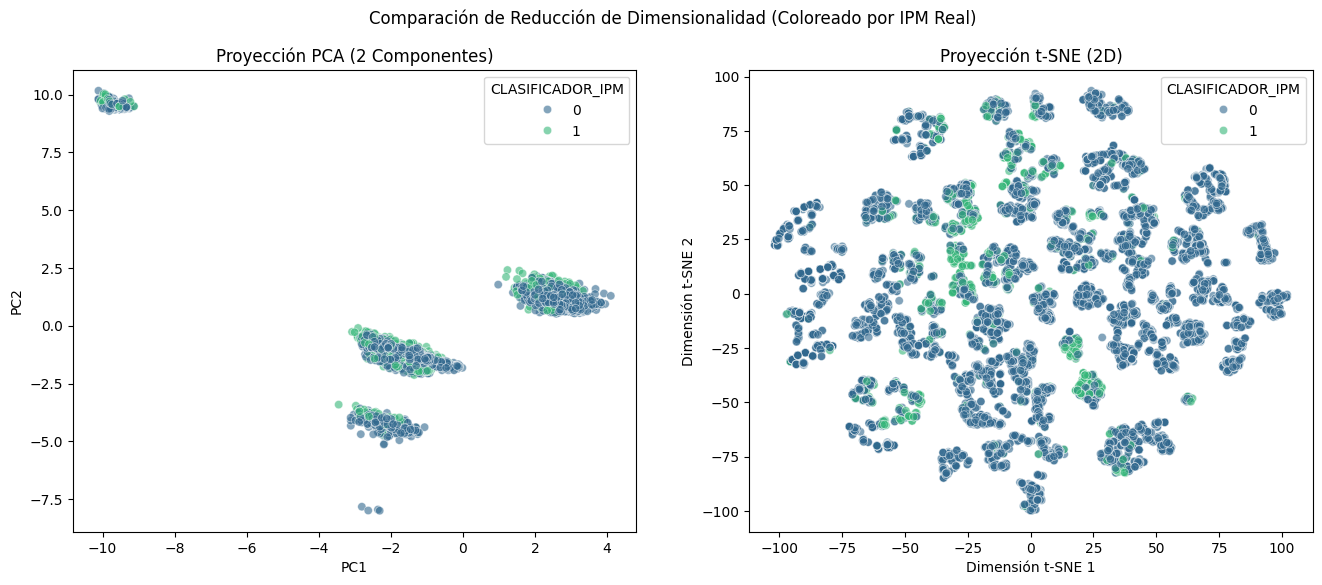

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Tomamos una muestra para agilizar los cálculos de t-SNE y algoritmos de clustering complejos
df_clustering = df_imputado_indicador.sample(n=10000, random_state=42).copy()
X_cluster = df_clustering.drop(columns=['CLASIFICADOR_IPM'])
y_true = df_clustering['CLASIFICADOR_IPM'].astype(int)

# Escalamos los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 1. Aplicamos PCA
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

# Graficamos la varianza explicada acumulada
plt.figure(figsize=(10, 5))
varianza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='--', color='b')
plt.axhline(y=0.85, color='r', linestyle=':', label='85% Varianza Explicada')
plt.axhline(y=0.90, color='g', linestyle=':', label='90% Varianza Explicada')
plt.title('Varianza Explicada Acumulada por Componentes Principales (PCA)')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid(True)
plt.legend()
plt.show()

# Seleccionamos las primeras 2 componentes para visualización directa
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# 2. Aplicamos t-SNE en 2D
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
X_tsne_2d = tsne.fit_transform(X_scaled)

# 3. Graficamos y comparamos PCA vs t-SNE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=y_true, palette='viridis', alpha=0.6, ax=ax1)
ax1.set_title('Proyección PCA (2 Componentes)')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')

sns.scatterplot(x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=y_true, palette='viridis', alpha=0.6, ax=ax2)
ax2.set_title('Proyección t-SNE (2D)')
ax2.set_xlabel('Dimensión t-SNE 1')
ax2.set_ylabel('Dimensión t-SNE 2')

plt.suptitle('Comparación de Reducción de Dimensionalidad (Coloreado por IPM Real)')
plt.show()


---
# **Búsqueda del K Óptimo (Método del Codo y Coeficiente de Silhouette)**
---
Utilizamos la inercia (WCSS) y el coeficiente de Silhouette para determinar formalmente el número adecuado de clústeres sobre nuestros datos proyectados.
```

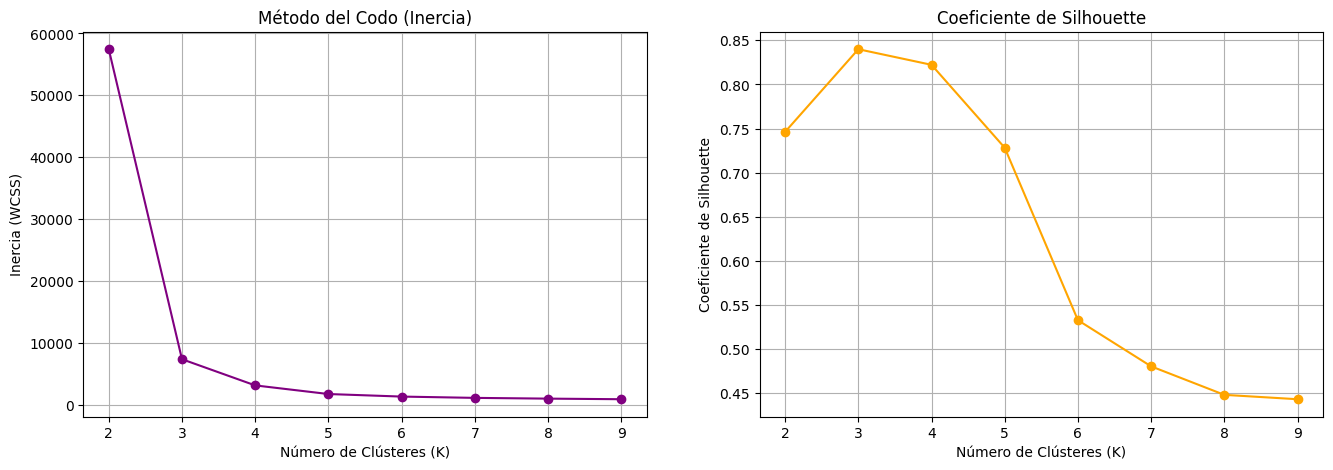

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rango_k = range(2, 10)
inercia = []
silhouette_scores = []

for k in rango_k:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_test.fit(X_pca_2d)
    inercia.append(kmeans_test.inertia_)
    # Usamos una sub-muestra para calcular el score de Silhouette debido a la complejidad O(N^2)
    sample_indices = np.random.choice(len(X_pca_2d), size=2000, replace=False)
    score = silhouette_score(X_pca_2d[sample_indices], kmeans_test.labels_[sample_indices])
    silhouette_scores.append(score)

# Graficamos el método del codo y Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(rango_k, inercia, marker='o', color='purple')
ax1.set_title('Método del Codo (Inercia)')
ax1.set_xlabel('Número de Clústeres (K)')
ax1.set_ylabel('Inercia (WCSS)')
ax1.grid(True)

ax2.plot(rango_k, silhouette_scores, marker='o', color='orange')
ax2.set_title('Coeficiente de Silhouette')
ax2.set_xlabel('Número de Clústeres (K)')
ax2.set_ylabel('Coeficiente de Silhouette')
ax2.grid(True)

plt.show()


---
# **Implementación y Comparación de Algoritmos (K-Means, DBSCAN, Jerárquico)**
---
Entrenamos y visualizamos el agrupamiento utilizando un $K=3$ determinado por el análisis previo, comparando los resultados de los tres algoritmos.
```

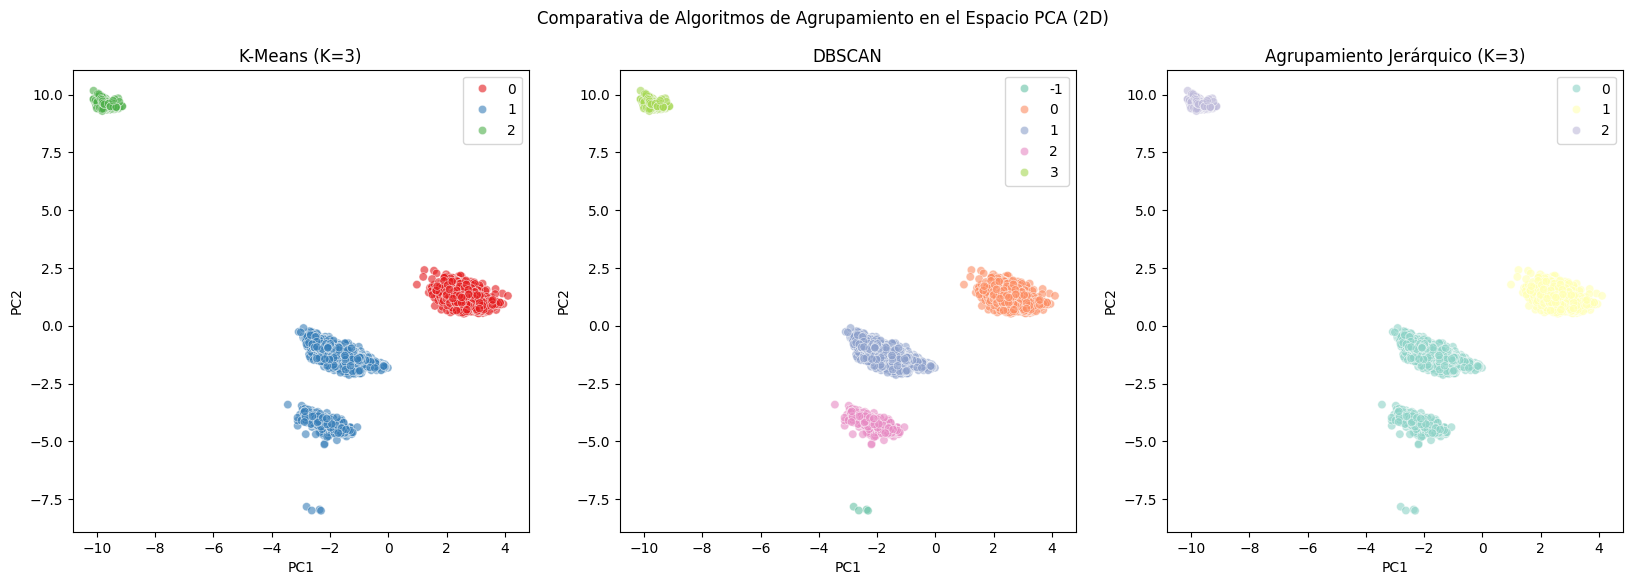

In [ ]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering

# Definimos el K óptimo basado en la inercia y Silhouette
k_optimo = 3

# 1. K-Means
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_pca_2d)

# 2. DBSCAN (Ajuste empírico de eps y min_samples)
dbscan = DBSCAN(eps=0.5, min_samples=15)
labels_dbscan = dbscan.fit_predict(X_pca_2d)

# 3. Clustering Jerárquico (Aglomerativo)
jerarquico = AgglomerativeClustering(n_clusters=k_optimo)
labels_jerarquico = jerarquico.fit_predict(X_pca_2d)

# Graficamos la comparación de los tres métodos de clustering
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=labels_kmeans, palette='Set1', alpha=0.6, ax=axes[0])
axes[0].set_title(f'K-Means (K={k_optimo})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=labels_dbscan, palette='Set2', alpha=0.6, ax=axes[1])
axes[1].set_title('DBSCAN')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=labels_jerarquico, palette='Set3', alpha=0.6, ax=axes[2])
axes[2].set_title(f'Agrupamiento Jerárquico (K={k_optimo})')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

plt.suptitle('Comparativa de Algoritmos de Agrupamiento en el Espacio PCA (2D)')
plt.show()